# Spotify 5000 songs – playlist clustering 🎧

**Goal:** group ~5,000 songs into coherent playlists using only Spotify audio features (no labels → unsupervised learning).

**Steps**
1. Import and clean the data
2. Select features and compare scalers
3. Choose k (elbow + silhouette)
4. K-Means clustering and cluster profiles (means, radar chart)
5. Visualise with PCA and t-SNE
6. Compare with DBSCAN and Agglomerative clustering
7. Conclusion

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler,QuantileTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage
import plotly.graph_objects as go



In [2]:
from sklearn import set_config
set_config (transform_output ='pandas')

## 2. Import and clean the data

In [3]:
songs_df = pd.read_csv("3_spotify_5000_songs.csv", skipinitialspace=True, index_col=0)


# strip the padding from the column names AND from the text values
songs_df.columns = songs_df.columns.str.strip()
for col in ["name", "artist"]:
    songs_df[col] = songs_df[col].str.strip()

# remove exact duplicates (same Spotify id)
before = len(songs_df)
songs_df = songs_df.drop_duplicates(subset="id")
print("exact duplicates removed:", before - len(songs_df))

# name + artist as a two-level index
songs_df = songs_df.set_index(["name", "artist"])

# keep one version per song (same name + artist)
before = len(songs_df)
songs_df = songs_df[~songs_df.index.duplicated(keep="first")]
print("other versions removed:  ", before - len(songs_df))

# drop the non-numeric / empty columns
songs_df = songs_df.drop(columns=["id", "html", "type","key","mode","time_signature"])

print("songs remaining:", len(songs_df))
songs_df.head()

exact duplicates removed: 64
other versions removed:   57
songs remaining: 5114


,,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
name,artist,,,,,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.658,0.2590,-13.141,0.0705,0.694,0.000059,0.975,0.306,110.376,256213
Saudade De Bahia,Antônio Carlos Jobim,0.742,0.3990,-12.646,0.0346,0.217,0.000002,0.107,0.693,125.039,191867
"Canta Canta, Minha Gente",Martinho Da Vila,0.851,0.7300,-11.048,0.3470,0.453,0.000063,0.124,0.905,93.698,152267
Mulher Eu Sei,Chico César,0.705,0.0502,-18.115,0.0471,0.879,0.000041,0.386,0.524,106.802,186227
Rosa Morena,Kurt Elling,0.651,0.1190,-19.807,0.0380,0.916,0.000343,0.104,0.402,120.941,273680


### 2.1 Checks after cleaning
5,235 rows → 64 exact duplicates (same Spotify id) and 57 repeated releases (same title + artist, kept the first) removed → **5,114 songs**. No missing values, no duplicated index.

In [4]:
len(songs_df)

5114

In [5]:
songs_df.info()

<class 'pandas.DataFrame'>
MultiIndex: 5114 entries, ('Se Eu Quiser Falar Com Deus', 'Gilberto Gil') to ('Ravel: Boléro, M. 81', 'Maurice Ravel')
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   danceability      5114 non-null   float64
 1   energy            5114 non-null   float64
 2   loudness          5114 non-null   float64
 3   speechiness       5114 non-null   float64
 4   acousticness      5114 non-null   float64
 5   instrumentalness  5114 non-null   float64
 6   liveness          5114 non-null   float64
 7   valence           5114 non-null   float64
 8   tempo             5114 non-null   float64
 9   duration_ms       5114 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 475.8+ KB


In [6]:
songs_df.isna().sum() 
#.isna(): Returns True for missing values and False for non-missing values.
#.sum(): Counts the True values in each column (True is treated as 1).

danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms         0
dtype: int64

In [7]:
songs_df.index.duplicated().sum()

np.int64(0)

In [8]:
songs_df[songs_df.index.duplicated(keep=False)].sort_index()

,,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
name,artist,,,,,,,,,,


---
## 3.&nbsp; Select features and scale the data 📐

### 3.1.&nbsp; Feature selection
We keep the audio features that describe *how a song sounds*. `key`, `mode` and `time_signature` are categorical, so we leave them out - a song in key 11 is not "far away" from a song in key 0. Feel free to experiment with adding them back.

In [9]:
audio_features_df=songs_df[["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]].copy()
audio_features_df1=songs_df[["danceability", "energy", "acousticness", "instrumentalness", "valence"]].copy()
audio_features_df1

,,danceability,energy,acousticness,instrumentalness,valence
name,artist,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.6580,0.25900,0.694,0.000059,0.3060
Saudade De Bahia,Antônio Carlos Jobim,0.7420,0.39900,0.217,0.000002,0.6930
"Canta Canta, Minha Gente",Martinho Da Vila,0.8510,0.73000,0.453,0.000063,0.9050
Mulher Eu Sei,Chico César,0.7050,0.05020,0.879,0.000041,0.5240
Rosa Morena,Kurt Elling,0.6510,0.11900,0.916,0.000343,0.4020
...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,0.2020,0.06940,0.917,0.715000,0.0655
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,0.1880,0.10100,0.855,0.426000,0.0355
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,0.0596,0.00093,0.951,0.969000,0.0344


### 3.2 Compare scalers
K-Means only sees distances, so every feature must be on a comparable scale (loudness is in dB, tempo in bpm, duration in ms).
We cluster with k = 5 after three scalers and compare the cluster sizes:
- MinMax on 10 features
- **StandardScaler on 5 features (our main model)**
- Quantile on 10 and on 5 features

In [10]:
minmax_scaler = MinMaxScaler()
scaled_minmax_df = minmax_scaler.fit_transform(audio_features_df)


In [11]:
# KMeans
random_seed=124
minmax_kmeans=KMeans(n_clusters=5,random_state=random_seed,n_init='auto')
minmax_kmeans.fit(scaled_minmax_df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",124
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 10)",

In [12]:
scaled_minmax_df["cluster"] = minmax_kmeans.labels_
scaled_minmax_df["cluster"].value_counts().sort_index()

cluster
0    1123
1     601
2     768
3     886
4    1736
Name: count, dtype: int64

#### 3.3 Main model: StandardScaler on the 5 mood features
danceability, energy, acousticness, instrumentalness, valence – they describe the *mood* of a song.
Dropped: key / mode / time_signature (categorical), loudness (≈ energy), speechiness / liveness / duration (skewed, describe the recording rather than the mood).

In [13]:
my_scaler = StandardScaler()
scaled_features_df = my_scaler.fit_transform(audio_features_df1)     # <- main model:-StandardScaler with 5 Features
scaled_features_df.describe().round(2)

,danceability,energy,acousticness,instrumentalness,valence
count,5114.00,5114.00,5114.00,5114.00,5114.00
mean,0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.32,-2.25,-0.82,-0.70,-1.59
25%,-0.93,-0.61,-0.81,-0.70,-0.89
50%,0.13,0.29,-0.55,-0.70,-0.10
75%,0.81,0.84,0.78,1.07,0.84
max,2.11,1.20,1.97,1.94,1.96


In [14]:
my_kmeans=KMeans(n_clusters=5,random_state=random_seed,n_init='auto')
my_kmeans.fit(scaled_features_df)

pd.Series(my_kmeans.labels_).value_counts().sort_index()

0    1054
1     860
2     630
3     720
4    1850
Name: count, dtype: int64

### 3.4 Comparison: Quantile transformer
Comparison only – these results are not used later. The second Quantile cell uses the same 5 features as the main model, so the only difference is the scaler.

In [15]:
quantile_scaler=QuantileTransformer(output_distribution="uniform",random_state=random_seed) # Quantile transformer on the 10 features - comparison only, not used later
scaled_quantile_df=quantile_scaler.fit_transform(audio_features_df)
scaled_quantile_df.describe().round(2)     # every column 0 ... 1


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,5114.00,5114.00,5114.00,5114.00,5114.00,5114.00,5114.00,5114.00,5114.00,5114.00
mean,0.50,0.50,0.50,0.50,0.50,0.47,0.50,0.50,0.50,0.50
std,0.29,0.29,0.29,0.29,0.29,0.33,0.29,0.29,0.29,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.25
50%,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50
75%,0.75,0.75,0.75,0.75,0.75,0.75,0.75,0.75,0.75,0.75
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [16]:

quantile_kmeans=KMeans(n_clusters=5,random_state=random_seed,n_init='auto')
quantile_kmeans.fit(scaled_quantile_df)

scaled_quantile_df["cluster"]=quantile_kmeans.labels_
scaled_quantile_df["cluster"].value_counts().sort_index()

cluster
0    1016
1     769
2    1192
3    1139
4     998
Name: count, dtype: int64

In [17]:
# Quantile transformer on the SAME 5 features - so the only difference to the main model is the scaler
quantile_scaler5 = QuantileTransformer(output_distribution="uniform", random_state=random_seed)
scaled_quantile5_df = quantile_scaler5.fit_transform(audio_features_df1)

In [18]:
quantile_kmeans5 = KMeans(n_clusters=5, random_state=random_seed, n_init='auto')
quantile_kmeans5.fit(scaled_quantile5_df)

scaled_quantile5_df["cluster"] = quantile_kmeans5.labels_
scaled_quantile5_df["cluster"].value_counts().sort_index()

cluster
0    1243
1    1353
2    1048
3     706
4     764
Name: count, dtype: int64

---
## 4. K-Means:choosing k

### 4.1.&nbsp; Inertia and the elbow method

In [19]:
# Set the maximum number of clusters to try
max_k = 20

# Create an empty list to store the inertia scores
inertia_list = []

# Iterate over the range of cluster numbers
for k in range(1, max_k + 1):

    # Create a KMeans object with the specified number of clusters
    myKMeans = KMeans(n_clusters=k,
                      random_state=random_seed,
                      n_init='auto')

    # Fit the KMeans model to the scaled data
    myKMeans.fit(scaled_features_df)

    # Append the inertia score to the list
    inertia_list.append(myKMeans.inertia_)

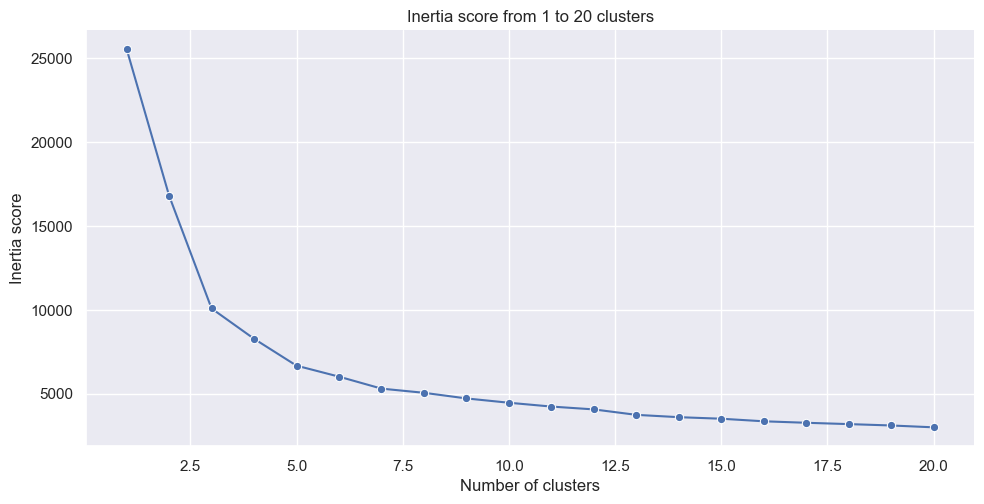

In [20]:
# Set the Seaborn theme to darkgrid
sns.set_theme(style='darkgrid')

(
# Create a line plot of the inertia scores
sns.relplot(y = inertia_list,
            x = range(1, max_k + 1),
            kind = 'line',
            marker = 'o',
            height = 5,
            aspect = 2)
# Set the title of the plot
.set(title=f"Inertia score from 1 to {max_k} clusters")
# Set the axis labels
.set_axis_labels("Number of clusters", "Inertia score")
);

### 4.2.&nbsp; The silhouette score

In [21]:
# Set the maximum number of clusters to try
max_k = 20

# Create an empty list to store the silhouette scores
sil_scores = []

for k in range(2, max_k+1):

    # Create a KMeans object with the specified number of clusters
    kmeans = KMeans(n_clusters = k,
                    random_state = random_seed,
                    )

    # Fit the KMeans model to the scaled data
    kmeans.fit(scaled_features_df)

    # Get the cluster labels
    labels = kmeans.labels_

    # Calculate the silhouette score
    sil_score = silhouette_score(scaled_features_df,labels)
    
    # Append the silhouette score to the list
    sil_scores.append(sil_score)
    

In [22]:
silhouette_score(scaled_features_df,my_kmeans.labels_)

0.36667720543969673

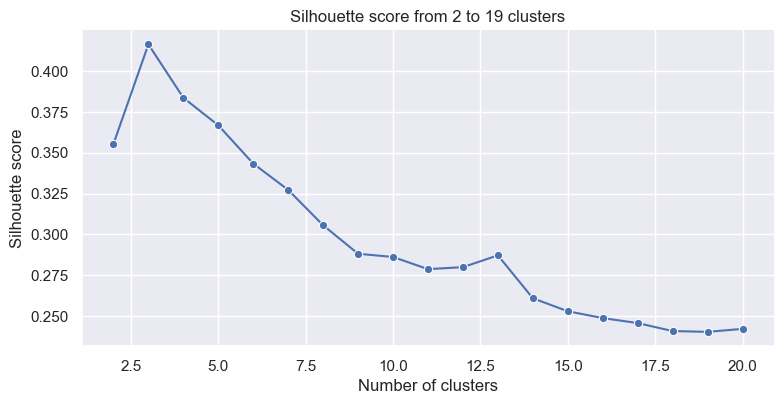

In [23]:
(
sns.relplot(y = sil_scores,
            x = range(2, max_k + 1),
            kind = 'line',
            marker = 'o',
            height = 4,
            aspect = 2)
.set(title=f"Silhouette score from 2 to {max_k - 1} clusters")
.set_axis_labels("Number of clusters", "Silhouette score")
);

---
## 5.&nbsp; Cluster with K-Means and explore the clusters 🫧

**Choosing k = 5**
- **Elbow:** inertia drops steeply up to k ≈ 4–5, then flattens.
- **Silhouette:** highest at k = 3 (0.42), then slowly decreasing (k = 4: 0.38, k = 5: 0.37).
- **Business sense:** k = 3 gives three playlists of ~1,700 songs that mix very different styles. k = 5 separates heavy metal from other high-energy music and gives five playlists of 600–1,850 songs that can be named. We accept a small silhouette loss (0.38 → 0.37) for clearly more meaningful playlists.

In [24]:
# Final model(chosen_k as 5  (see the elbow *silhouette above))
my_kmeans = KMeans(n_clusters = 5, # always choose the number of k here
                   random_state = random_seed,n_init='auto')

# Fit the model to the data
my_kmeans.fit(scaled_features_df)

# Obtain the cluster output
clusters = my_kmeans.labels_

# Attach the cluster output to our original DataFrame
scaled_features_df["cluster"] = my_kmeans.labels_

scaled_features_df

,,danceability,energy,acousticness,instrumentalness,valence,cluster
name,artist,,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,0.695680,-1.360008,1.126802,-0.702075,-0.485939,3
Saudade De Bahia,Antônio Carlos Jobim,1.080960,-0.877073,-0.209223,-0.702228,0.907870,4
"Canta Canta, Minha Gente",Martinho Da Vila,1.580907,0.264722,0.451787,-0.702063,1.671404,4
Mulher Eu Sei,Chico César,0.911253,-2.080270,1.644966,-0.702124,0.299204,3
Rosa Morena,Kurt Elling,0.663574,-1.842942,1.748599,-0.701311,-0.140188,3
...,...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,-1.395839,-2.014039,1.751400,1.219084,-1.352118,2
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,-1.460053,-1.905034,1.577745,0.442496,-1.460165,2
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,-2.048981,-2.250228,1.846631,1.901622,-1.464127,2


| Cluster | Songs | Profile | Typical artists | Playlist |
|---|---|---|---|---|
| 0 | 1,850 | danceable, energetic, happy (high valence) | Daddy Yankee, Don Omar, Rihanna | **Dance Beats** |
| 1 | 860 | very high energy, instrumental, low valence | Cannibal Corpse, Entombed, Deicide | **Heavy Metal** |
| 2 | 630 | very acoustic, instrumental, low energy | Bach, Mozart, Alexis Ffrench | **Acoustic Classics** |
| 3 | 1,054 | high energy, vocal, low acousticness | Obituary, Death, Martin Garrix | **Electric Vibes** |
| 4 |720 | acoustic, mid energy, vocal | Caetano Veloso, Stan Getz, Frank Sinatra | **Melodic Music** |

In [25]:
scaled_features_df[["cluster"]].sort_values(by='cluster')
 #who is in each cluster

,,cluster
name,artist,
If I Lose Myself - Alesso vs OneRepublic,OneRepublic,0
"I'll Be There for You - Theme From ""Friends""",The Rembrandts,0
Grotesque Impalement,Dying Fetus,0
Ironic - 2015 Remaster,Alanis Morissette,0
Flesh and the Power It Holds,Death,0
...,...,...
Change the World - 2015 Remaster,Eric Clapton,4
Step by Step,New Kids On The Block,4
Life,Des'ree,4


### 5.1 Cluster profiles
Mean of each standardised feature per cluster: 0 = average song, positive = above average, negative = below average.

In [26]:
cluster_feat_means=scaled_features_df.groupby(by="cluster").mean()
cluster_feat_means
#some groups of songs have a more diverse range of preferences than others.

,danceability,energy,acousticness,instrumentalness,valence
cluster,,,,,
0,-0.324662,0.625041,-0.676925,-0.561683,-0.560845
1,-1.039651,0.849530,-0.783787,1.398224,-0.731432
2,-0.914563,-1.815067,1.799909,1.448920,-1.055215
3,0.159830,-0.991207,1.215662,-0.550220,0.112165
4,0.917509,0.252850,-0.336045,-0.609254,0.975237



### 5.2.&nbsp; Radar Chart

In [27]:
scatter_objects = []

# labels for the arms of the chart (feature names, without 'cluster')
categories = cluster_feat_means.columns

for cluster in cluster_feat_means.index:

    # mean value of every feature for this cluster
    cluster_means = cluster_feat_means.loc[cluster]

    cluster_scatter = go.Scatterpolar(
        r = cluster_means,
        theta = categories,
        fill = 'toself',
        name = f'Cluster {cluster}'
    )
    scatter_objects.append(cluster_scatter)

fig = go.Figure()
fig.add_traces(scatter_objects)
fig.update_layout(
    title_text = 'Radar chart of mean audio features by cluster',
    height = 650,
    width = 700,
    polar = dict(radialaxis = dict(visible = True)),
    showlegend = True
)
fig.show()

## 6. PCA
PCA shows how much information the 5 features share and lets us project the clusters onto 2 dimensions.
Result: 4 of 5 components are needed for 95 % of the variance, so the features carry largely independent information.

In [28]:
# features only - the cluster column must NOT go into PCA
X = scaled_features_df.drop(columns="cluster")
# Initialise the PCA object
pca = PCA()
pca.fit(X)# Fit the PCA object to the data
pca_basic_df = pca.transform(X)

# Transform scaled_features_df based on the fit calculations


pca_basic_df

,,pca0,pca1,pca2,pca3,pca4
name,artist,,,,,
Se Eu Quiser Falar Com Deus,Gilberto Gil,-0.489839,-1.763275,-0.808278,0.573656,0.029081
Saudade De Bahia,Antônio Carlos Jobim,1.077556,-1.251338,0.071067,0.279046,-0.699263
"Canta Canta, Minha Gente",Martinho Da Vila,1.868529,-1.370568,0.651412,-0.104610,0.504777
Mulher Eu Sei,Chico César,-0.455699,-2.823298,-0.399414,0.254463,-0.208250
Rosa Morena,Kurt Elling,-0.748020,-2.514148,-0.669377,0.273338,0.051008
...,...,...,...,...,...,...
"1812 Festival Overture, Op. 49: 1812 Overture, Op. 49",Pyotr Ilyich Tchaikovsky,-3.350480,-1.033438,-0.172591,-0.093205,-0.233073
"Winter Fragments pour ensemble instrumental, sons de synthèse et dispositif électronique",Tristan Murail,-2.953602,-0.986649,-0.867007,-0.221844,-0.282698
"Schoenberg: 5 Orchestral Pieces, Op. 16: No. 3 Farben (Colours)",Arnold Schoenberg,-4.178688,-0.795010,0.177967,-0.349147,-0.429743


###&nbsp; Identifying the most informative principal components
Principal component analysis (PCA) assumes that variance is information. This means that PCA believes that the directions in which the data varies the most are the most important.

When we fit PCA to our data, it calculates all of the principal components. We can see how much variance each principal component explains using the `explained_variance_ratio_` attribute.
> The principal components are ranked in order of decreasing variance, with the first principal component explaining the most variance in the data

In [29]:
# Get the variance explained by each principal component
explained_variance_array = pca.explained_variance_ratio_            # 1-D, length 5
cumulative_sum_of_variance = np.cumsum(explained_variance_array)
print(explained_variance_array.shape, cumulative_sum_of_variance.shape)   # (5,) (5,)


(5,) (5,)


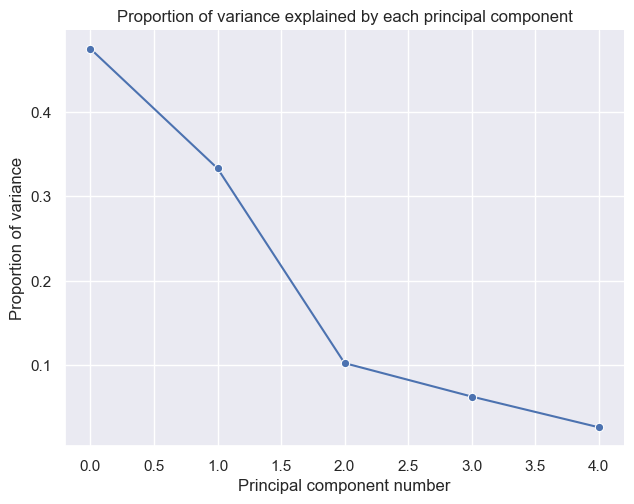

In [30]:
# Create a Pandas DataFrame from the variance explained array
explained_variance_array_df = pd.DataFrame(explained_variance_array, columns=["Variance explained"])

(
  # Create a line chart with sns.relplot
  sns.relplot(
      kind = 'line',
      data = explained_variance_array_df,
      x = explained_variance_array_df.index,
      y = "Variance explained",
      marker = 'o',
      aspect = 1.3)
  # Set the title of the plot
  .set(title = "Proportion of variance explained by each principal component")
  # Set the axis labels
  .set_axis_labels("Principal component number", "Proportion of variance")
);

In [31]:
cumulative_sum_of_variance = np.cumsum(explained_variance_array)
print("shapes:", explained_variance_array.shape, cumulative_sum_of_variance.shape)   # (10,) (10,)


#cumulative_sum_of_variance

shapes: (5,) (5,)


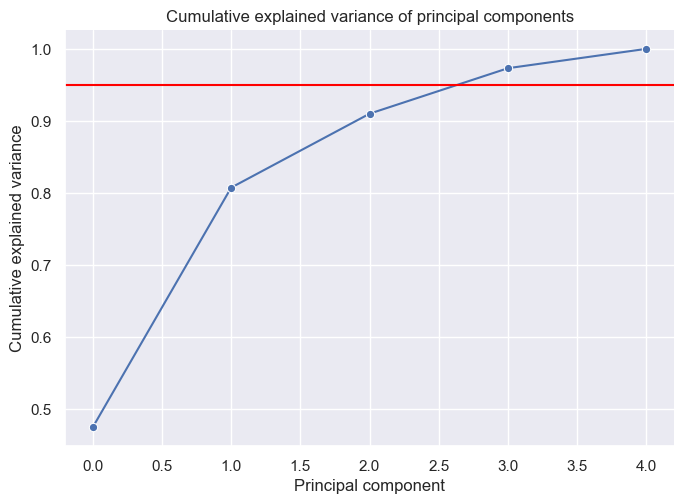

In [32]:
(
  # Create a cumulative explained variance plot
  sns.relplot(
      kind = "line",  # Create a line plot
      x = range(len(explained_variance_array)),  # Set the x-axis to be the principal component index
      y = cumulative_sum_of_variance,  # Set the y-axis to be the cumulative explained variance
      marker = "o",  # Use a circle marker for the data points
      aspect = 1.4,  # Set the aspect ratio of the plot to be 1.4
  )
  # Set the title of the plot
  .set(title="Cumulative explained variance of principal components")
  # Set the axis labels
  .set_axis_labels("Principal component", "Cumulative explained variance")
);

# Add a horizontal red line at 0.95 on the y axis
plt.axhline(y = 0.95,
            color = 'red');

In [33]:

# keep 95 % of the variance
pca_variance = PCA(n_components=0.95)
pca_variance_df = pca_variance.fit_transform(X)
print("components for 95 %:", pca_variance.n_components_)

components for 95 %: 4


In [34]:
X.shape #(5114, 5)
X.columns

Index(['danceability', 'energy', 'acousticness', 'instrumentalness',
       'valence'],
      dtype='str')

## 7. t-SNE
A 2-D map that keeps similar songs close together. If the colours form separate regions, the K-Means clusters reflect real structure in the data.

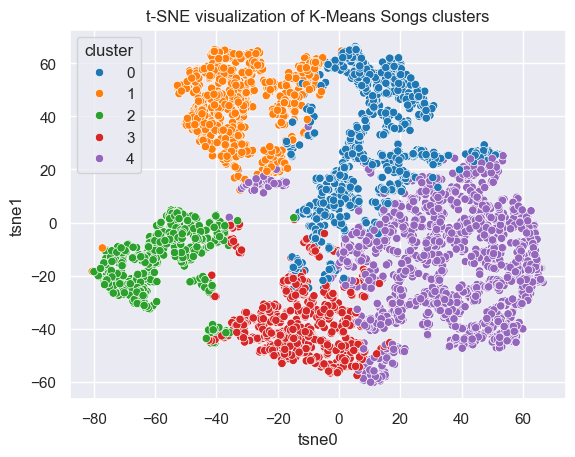

In [35]:
tsne=TSNE(n_components=2,random_state=random_seed,perplexity=30)
tsne_results=tsne.fit_transform(X)
# t-SNE returns a DataFrame : tsne0,tsne1,songindex
tsne_results["cluster"]=scaled_features_df["cluster"].values

sns.scatterplot(data=tsne_results,x="tsne0",y="tsne1",hue="cluster",palette="tab10")
plt.title("t-SNE visualization of K-Means Songs clusters")
plt.show()

## 8. DBSCAN
DBSCAN does not need k. It needs `min_samples` (rule of thumb: 2 × 5 features = 10) and `eps`, read from the k-distance graph (knee) and confirmed with a scan.

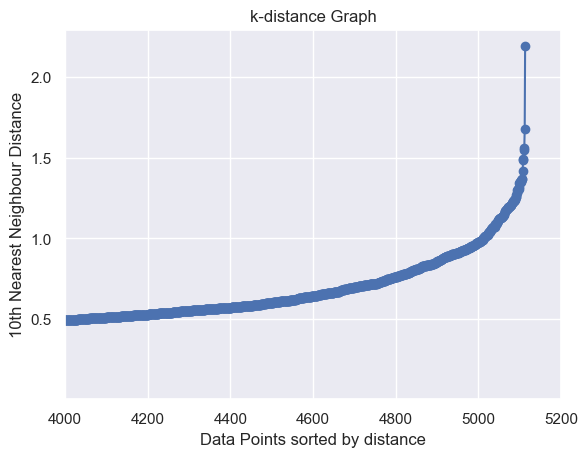

In [36]:
min_samples = 10 #2*number of features(5)
neighbours = NearestNeighbors(n_neighbors=min_samples).fit(X)
distances, indices = neighbours.kneighbors(X)
sorted_distances = np.sort(distances[:, -1])

plt.plot(range(len(sorted_distances)), sorted_distances, marker="o")
plt.xlim(4000, 5200)                              # zoom on the knee
plt.title("k-distance Graph"); plt.xlabel("Data Points sorted by distance")
plt.ylabel(f"{min_samples}th Nearest Neighbour Distance"); plt.show()

In [37]:
for eps in[0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
    labels=DBSCAN(eps=eps,min_samples=10).fit(X).labels_
    print(eps,"clusters:",labels.max()+1,"Noise:",(labels==-1).sum())

0.2 clusters: 21 Noise: 4346
0.3 clusters: 11 Noise: 2460
0.4 clusters: 9 Noise: 1237
0.5 clusters: 3 Noise: 567
0.6 clusters: 2 Noise: 315
0.7 clusters: 1 Noise: 209
0.8 clusters: 1 Noise: 106
0.9 clusters: 1 Noise: 50
1.0 clusters: 1 Noise: 19


In [38]:
dbscan=DBSCAN(eps=.50,min_samples=min_samples)
dbscan.fit(X)
scaled_features_df['dbscan']=dbscan.labels_
         # -1 = noise
scaled_features_df["dbscan"].value_counts().sort_index()


dbscan
-1     567
 0    4049
 1     492
 2       6
Name: count, dtype: int64

## 9. Perform Agglomerative clustering (ward)
A second algorithm with the same k = 5, used to check whether K-Means found real structure.

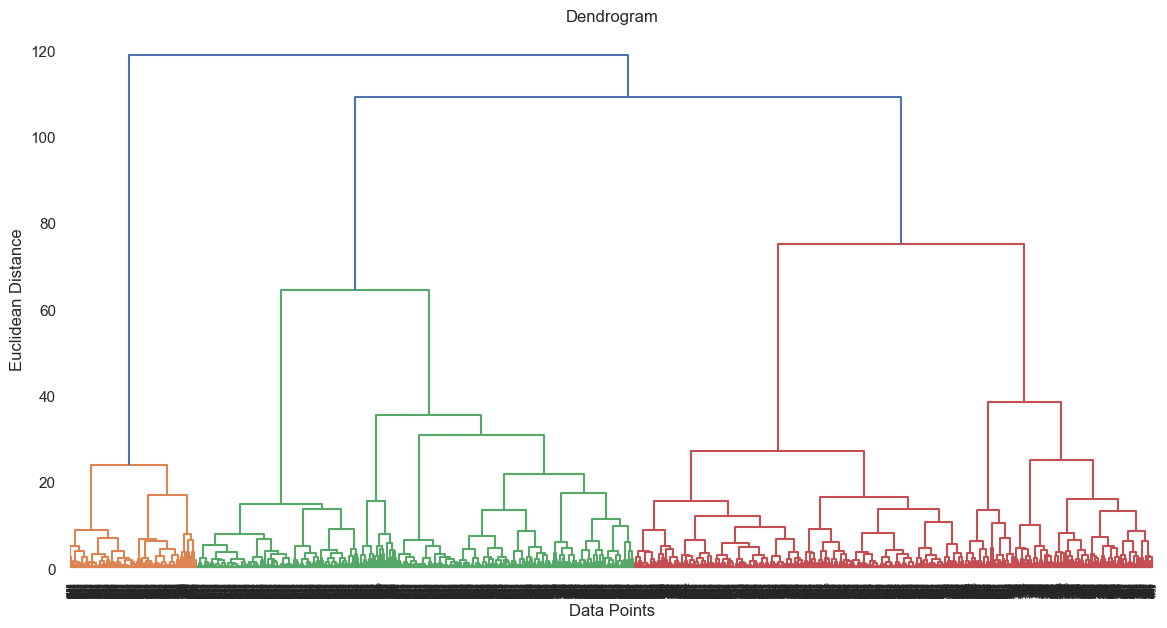

In [39]:
# Perform WARD agglomerative clustering using scipy to plot dendrogram
linked = linkage(X, method='ward')

plt.figure(figsize=(14, 7))
dendrogram(linked,
           orientation='top',
           
           show_contracted=True,
           distance_sort=True,
           show_leaf_counts=False)
plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.xticks(rotation=90)
plt.ylabel('Euclidean Distance')
plt.show()

In [40]:
agg_clustering = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')   # same k as my_kmeans
agg_clustering.fit(X)
scaled_features_df["agglocluster"] = agg_clustering.labels_
scaled_features_df["agglocluster"].value_counts().sort_index()

pd.crosstab(scaled_features_df["cluster"], scaled_features_df["agglocluster"])   # do the two methods agree?

agglocluster,0,1,2,3,4
cluster,,,,,
0,19,52,965,0,18
1,2,0,105,3,750
2,62,0,0,568,0
3,668,19,3,30,0
4,145,1482,221,2,0


## 10. Conclusion

**1. Representing songs**
Each song is a point in a 5-dimensional space of mood features: danceability, energy, acousticness, instrumentalness and valence. Categorical, redundant and skewed features were removed. Features were standardised so that each one has an equal influence.

**2. Why distance matters**
All three algorithms assume that songs close together sound similar. The feature selection and the scaler define what "close" means. Without scaling, song duration alone would decide the clusters. DBSCAN's eps is itself a distance and has to be re-read whenever the scaler changes.

**3. How clustering created the playlists**
K-Means with k = 5 (elbow + silhouette + playlist size) gives five playlists with distinct audio profiles: **Dance Beats (1,850), Electric Vibes (1,054), Heavy Metal (860), Melodic Music (720) and Acoustic Classics (630)**.
- Silhouette 0.37
- Agglomerative clustering (ward) agrees for 87 % of the songs
- t-SNE shows the same regions

DBSCAN found no density gaps: the songs form a continuum. Its value here is detecting unusual tracks.

**4. Was unsupervised learning useful?**
Yes, as a fast, scalable first draft of playlists without any labels. The limits:
- clusters overlap at their edges (silhouette 0.37)
- audio features capture sound, not genre, language or lyrics, so some songs land in a surprising playlist
- k and the features are human decisions, and only listening can confirm that a playlist works

**Next steps:** a finer k to split the largest playlist, genre metadata as a sanity check, and a listener test.